# Tarea 8 · Redes neuronales para regresión

**Python · Concrete_Data.csv · Basada en `redneuronalregresion.ipynb`**

Una red densa de TensorFlow/Keras estima la resistencia a compresión. Se mantienen las capas del ejemplo, el escalado de entradas y salida, la parada temprana, el diagnóstico y los dos métodos de importancia.

## 1. Carga y exploración de los datos

La respuesta es **resistencia a compresión (MPa)**. Los predictores son cemento, escoria de alto horno, ceniza volante, agua, superplastificante, agregado grueso y agregado fino (todos en **kg/m³**), y edad de curado (**días**). Se conservan los ocho predictores. Las columnas de Boston y sus unidades no corresponden a esta base.

Se retiran únicamente duplicados exactos. Los ensayos distintos de la misma receta se conservan y se asignan juntos en cada partición. Las proporciones solicitadas se aplican a recetas, por lo que el porcentaje de filas puede variar.

In [1]:
from pathlib import Path
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit

%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 100, "savefig.bbox": "tight"})
print(f"Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
from tempfile import TemporaryDirectory

from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import callbacks, layers, regularizers

SEED = 42
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
print(f"TensorFlow {tf.__version__} | Keras {keras.__version__} | Semilla {SEED}")

Python 3.12.14 | pandas 3.0.6 | scikit-learn 1.9.1


TensorFlow 2.21.0 | Keras 3.15.1 | Semilla 42


In [2]:
ruta = next(
    (carpeta / "Concrete_Data.csv" for carpeta in (Path.cwd(), *Path.cwd().parents)
     if (carpeta / "Concrete_Data.csv").is_file()),
    None,
)
if ruta is None:
    raise FileNotFoundError("Abre el cuaderno dentro del proyecto que contiene Concrete_Data.csv.")

original = pd.read_csv(ruta)
columnas = [
    "cemento", "escoria", "ceniza_volante", "agua", "superplastificante",
    "agregado_grueso", "agregado_fino", "edad_dias", "resistencia_mpa",
]
if original.shape[1] != len(columnas):
    raise ValueError(f"Se esperaban 9 columnas, se encontraron {original.shape[1]}.")

df = original.set_axis(columnas, axis=1).apply(pd.to_numeric)
if not np.isfinite(df.to_numpy()).all():
    raise ValueError("Se encontraron valores faltantes o no finitos.")

print(f"Archivo: {ruta.name} | Filas originales: {len(df)} | Columnas: {df.shape[1]}")
print(f"Valores faltantes: {df.isna().sum().sum()} | Duplicados exactos: {df.duplicated().sum()}")
df = df.drop_duplicates().reset_index(drop=True)
TARGET = "resistencia_mpa"
X = df.drop(columns=TARGET)
y = df[TARGET]
# Identificador de receta basado únicamente en las siete cantidades de mezcla.
grupos = df.groupby(columnas[:7], sort=False).ngroup()
print(f"Filas analizadas: {len(df)} | Recetas distintas: {grupos.nunique()}")
display(df.head(3))
display(df.describe().T.round(2))

Archivo: Concrete_Data.csv | Filas originales: 1030 | Columnas: 9
Valores faltantes: 0 | Duplicados exactos: 25
Filas analizadas: 1005 | Recetas distintas: 428


,cemento,escoria,ceniza_volante,agua,superplastificante,agregado_grueso,agregado_fino,edad_dias,resistencia_mpa
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535


,count,mean,std,min,25%,50%,75%,max
cemento,1005.0,278.63,104.35,102.00,190.68,265.0,349.00,540.0
escoria,1005.0,72.04,86.17,0.00,0.00,20.0,142.50,359.4
ceniza_volante,1005.0,55.54,64.21,0.00,0.00,0.0,118.27,200.1
agua,1005.0,182.07,21.34,121.75,166.61,185.7,192.94,247.0
superplastificante,1005.0,6.03,5.92,0.00,0.00,6.1,10.00,32.2
agregado_grueso,1005.0,974.38,77.58,801.00,932.00,968.0,1031.00,1145.0
agregado_fino,1005.0,772.69,80.34,594.00,724.30,780.0,822.20,992.6
edad_dias,1005.0,45.86,63.73,1.00,7.00,28.0,56.00,365.0
resistencia_mpa,1005.0,35.25,16.28,2.33,23.52,33.8,44.87,82.6


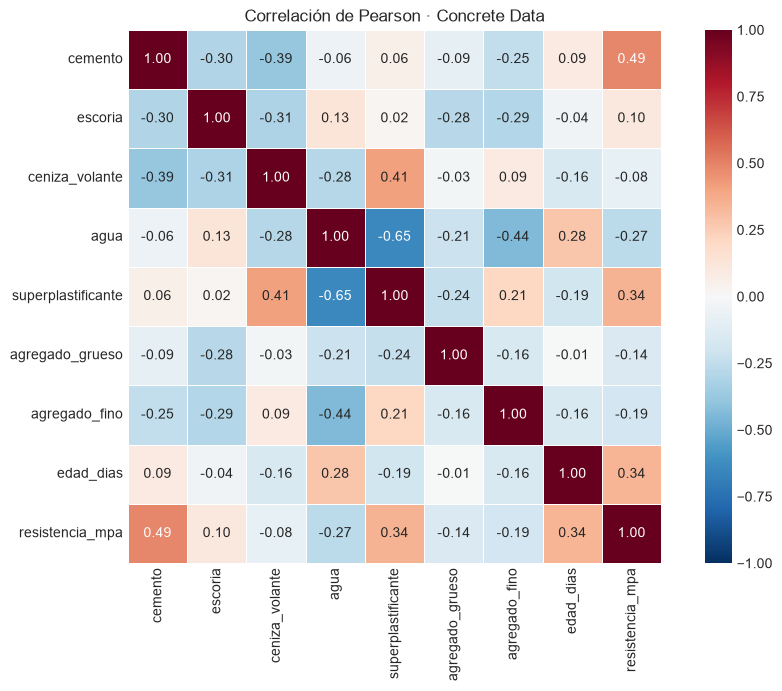

In [3]:
fig, ax = plt.subplots(figsize=(10, 6.8), layout="constrained")
corr = df.corr()
sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1,
            cmap="RdBu_r", square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlación de Pearson · Concrete Data")
plt.show()

## 2. Distribución de la respuesta y correlaciones con los predictores

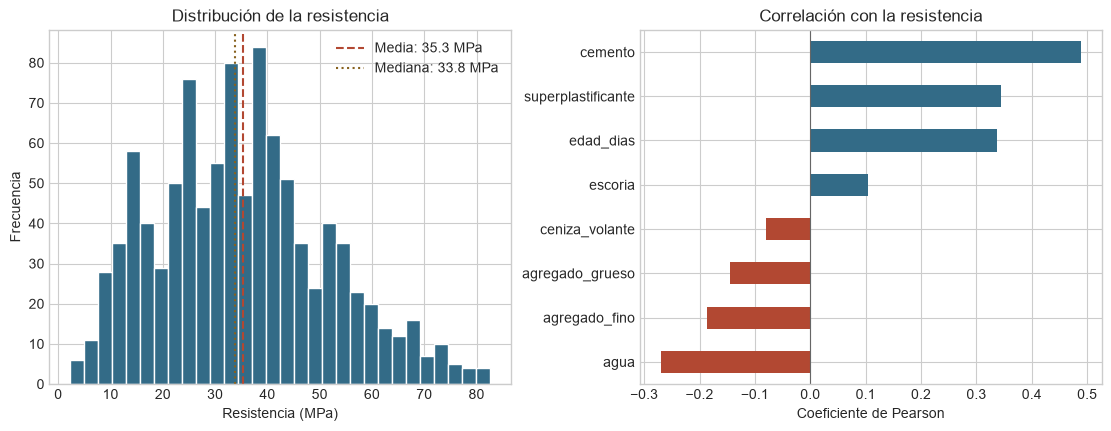

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
axes[0].hist(y, bins=30, color="#336b87", edgecolor="white")
axes[0].axvline(y.mean(), color="#b24832", linestyle="--", label=f"Media: {y.mean():.1f} MPa")
axes[0].axvline(y.median(), color="#87611e", linestyle=":", label=f"Mediana: {y.median():.1f} MPa")
axes[0].set(title="Distribución de la resistencia", xlabel="Resistencia (MPa)", ylabel="Frecuencia")
axes[0].legend()
corr_y = df.corr()[TARGET].drop(TARGET).sort_values()
corr_y.plot.barh(ax=axes[1], color=["#b24832" if r < 0 else "#336b87" for r in corr_y])
axes[1].axvline(0, color="0.4", linewidth=0.8)
axes[1].set(title="Correlación con la resistencia", xlabel="Coeficiente de Pearson")
plt.show()

## 3. Partición y escalado

Se conserva la división aproximada 70/15/15 del ejemplo, aplicada a recetas. Los escaladores de X e y se ajustan únicamente con entrenamiento. Las métricas de prueba se calculan en MPa después de invertir la transformación de la respuesta.

In [5]:
def dividir(indices, proporcion, semilla):
    divisor = GroupShuffleSplit(n_splits=1, test_size=proporcion, random_state=semilla)
    parte_a, parte_b = next(divisor.split(X.iloc[indices], groups=grupos.iloc[indices]))
    a, b = indices[parte_a], indices[parte_b]
    assert set(grupos.iloc[a]).isdisjoint(grupos.iloc[b])
    return a, b


def mostrar_particiones(**particiones):
    display(pd.DataFrame([
        {
            "Conjunto": nombre,
            "Filas": len(indices),
            "% de filas": 100 * len(indices) / len(df),
            "Recetas": grupos.iloc[indices].nunique(),
        }
        for nombre, indices in particiones.items()
    ]).round(2))

resto, prueba = dividir(np.arange(len(df)), 0.15, SEED)
entrenamiento, validacion = dividir(resto, 0.15 / 0.85, SEED)
assert set(grupos.iloc[entrenamiento]).isdisjoint(grupos.iloc[prueba])
assert set(grupos.iloc[validacion]).isdisjoint(grupos.iloc[prueba])
mostrar_particiones(Entrenamiento=entrenamiento, Validación=validacion, Prueba=prueba)

X_train, X_val, X_test = X.iloc[entrenamiento], X.iloc[validacion], X.iloc[prueba]
y_train, y_val, y_test = y.iloc[entrenamiento], y.iloc[validacion], y.iloc[prueba]

scaler_X = StandardScaler().fit(X_train)
scaler_y = StandardScaler().fit(y_train.to_numpy().reshape(-1, 1))
X_train_sc, X_val_sc, X_test_sc = [
    scaler_X.transform(parte).astype("float32") for parte in (X_train, X_val, X_test)
]
y_train_sc, y_val_sc = [
    scaler_y.transform(parte.to_numpy().reshape(-1, 1)).astype("float32")
    for parte in (y_train, y_val)
]
print(f"Media de entrenamiento usada para escalar y: {scaler_y.mean_[0]:.3f} MPa")
print(f"Desviación usada para escalar y: {scaler_y.scale_[0]:.3f} MPa")

,Conjunto,Filas,% de filas,Recetas
0,Entrenamiento,705,70.15,298
1,Validación,162,16.12,65
2,Prueba,138,13.73,65


Media de entrenamiento usada para escalar y: 35.107 MPa
Desviación usada para escalar y: 15.789 MPa


## 4. Arquitectura de la red

Cuatro capas ocultas ReLU de 128, 64, 32 y 16 neuronas. Las dos primeras usan regularización L2 y normalización por lotes. Se conserva el Dropout de las tres primeras y una salida lineal para la respuesta continua. El optimizador es Adam y la pérdida se calcula con MSE más la penalización L2.

In [6]:
def construir_red(dimension):
    modelo = keras.Sequential([
        keras.Input(shape=(dimension,)),
        layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(0.001), name="oculta_1"),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(0.001), name="oculta_2"),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(32, activation="relu", name="oculta_3"),
        layers.Dropout(0.1),
        layers.Dense(16, activation="relu", name="oculta_4"),
        layers.Dense(1, activation="linear", name="salida"),
    ])
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mse", metrics=["mae"])
    return modelo


modelo = construir_red(X_train_sc.shape[1])
modelo.summary(line_length=85)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃ Layer (type)                        ┃ Output Shape               ┃        Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ oculta_1 (Dense)                    │ (None, 128)                │          1,152 │
├─────────────────────────────────────┼────────────────────────────┼────────────────┤
│ batch_normalization                 │ (None, 128)                │            512 │
│ (BatchNormalization)                │                            │                │
├─────────────────────────────────────┼────────────────────────────┼────────────────┤
│ dropout (Dropout)                   │ (None, 128)                │              0 │
├─────────────────────────────────────┼────────────────────────────┼────────────────┤
│ oculta_2 (Dense)                    │ (None, 64)                 │          8,256 │
├─────────────────────────────────────┼────────────────────────────┼────────────────┤
│ batch_normalization_1               │ (None, 64)                 │            256 │
│ (BatchNormalization)                │                            │                │
├─────────────────────────────────────┼────────────────────────────┼────────────────┤
│ dropout_1 (Dropout)                 │ (None, 64)                 │              0 │
├─────────────────────────────────────┼────────────────────────────┼────────────────┤
│ oculta_3 (Dense)                    │ (None, 32)                 │          2,080 │
├─────────────────────────────────────┼────────────────────────────┼────────────────┤
│ dropout_2 (Dropout)                 │ (None, 32)                 │              0 │
├─────────────────────────────────────┼────────────────────────────┼────────────────┤
│ oculta_4 (Dense)                    │ (None, 16)                 │            528 │
├─────────────────────────────────────┼────────────────────────────┼────────────────┤
│ salida (Dense)                      │ (None, 1)                  │             17 │
└─────────────────────────────────────┴────────────────────────────┴────────────────┘

 Total params: 12,801 (50.00 KB)

 Trainable params: 12,417 (48.50 KB)

 Non-trainable params: 384 (1.50 KB)

## 5. Callbacks y entrenamiento

La pérdida de validación controla `EarlyStopping` (paciencia 30), `ReduceLROnPlateau` (paciencia 15, factor 0.5) y `ModelCheckpoint`. Se permiten hasta 500 épocas con lotes de 32. El checkpoint se guarda temporalmente y se recarga antes de evaluar.

In [7]:
opciones = tf.data.Options()
opciones.threading.private_threadpool_size = 1

lotes_train = (
    tf.data.Dataset.from_tensor_slices((X_train_sc, y_train_sc))
    .shuffle(len(X_train_sc), seed=SEED)
    .batch(32)
    .with_options(opciones)
)
lotes_val = tf.data.Dataset.from_tensor_slices((X_val_sc, y_val_sc)).batch(32).with_options(opciones)

parada = callbacks.EarlyStopping(monitor="val_loss", patience=30, restore_best_weights=True, verbose=1)
reducir_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=15, min_lr=1e-6, verbose=1,
)
with TemporaryDirectory() as carpeta:
    archivo = Path(carpeta) / "mejor_modelo_concrete.keras"
    checkpoint = callbacks.ModelCheckpoint(archivo, monitor="val_loss", save_best_only=True)
    historia = modelo.fit(
        lotes_train, validation_data=lotes_val, epochs=500,
        callbacks=[parada, reducir_lr, checkpoint], shuffle=False, verbose=0,
    )
    modelo = keras.models.load_model(archivo)

historial = pd.DataFrame(historia.history, index=pd.RangeIndex(1, len(historia.epoch) + 1, name="Época"))
mejor_epoca = historial["val_loss"].idxmin()
print(f"Épocas ejecutadas: {len(historial)} | Menor pérdida de validación en época {mejor_epoca}")
display(historial.loc[[mejor_epoca]].round(5))
display(historial.tail().round(5))


Epoch 160: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.



Epoch 178: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.



Epoch 193: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.


Epoch 194: early stopping


Restoring model weights from the end of the best epoch: 164.


Épocas ejecutadas: 194 | Menor pérdida de validación en época 164


,loss,mae,val_loss,val_mae,learning_rate
Época,,,,,
164,0.14942,0.25676,0.12955,0.21362,0.0005


,loss,mae,val_loss,val_mae,learning_rate
Época,,,,,
190,0.14215,0.26465,0.14762,0.22845,0.00025
191,0.13930,0.25113,0.14637,0.23344,0.00025
192,0.13293,0.24795,0.13891,0.22284,0.00025
193,0.14420,0.26131,0.13815,0.22267,0.00025
194,0.13186,0.24707,0.13874,0.22292,0.00013


## 6. Curvas de aprendizaje

La pérdida usa la respuesta estandarizada e incluye la penalización L2. Para interpretar el MAE de las curvas se multiplica por la desviación del escalador de y, lo que lo devuelve a MPa.

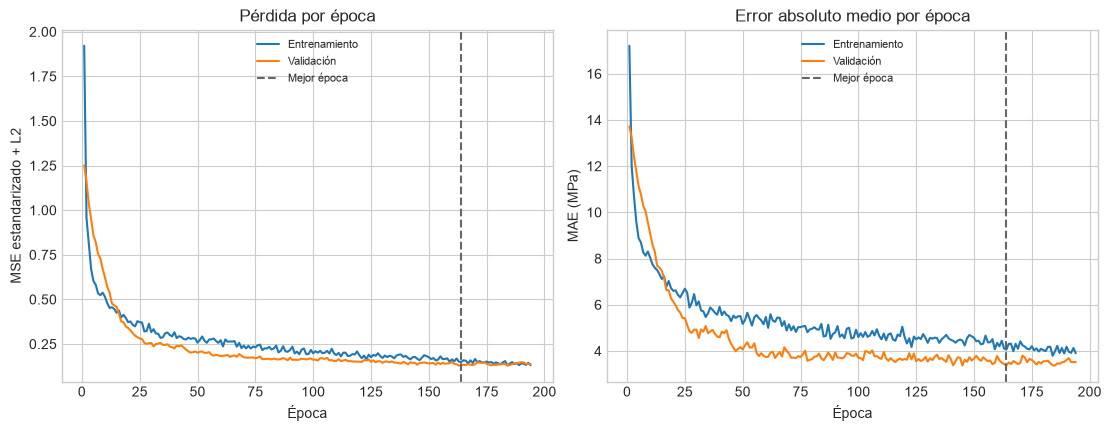

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
for prefijo, etiqueta in (("", "Entrenamiento"), ("val_", "Validación")):
    axes[0].plot(historial.index, historial[f"{prefijo}loss"], label=etiqueta)
    axes[1].plot(historial.index, historial[f"{prefijo}mae"] * scaler_y.scale_[0], label=etiqueta)
axes[0].set(title="Pérdida por época", ylabel="MSE estandarizado + L2")
axes[1].set(title="Error absoluto medio por época", ylabel="MAE (MPa)")
for ax in axes:
    ax.axvline(mejor_epoca, color="0.4", linestyle="--", label="Mejor época")
    ax.set_xlabel("Época")
    ax.legend(fontsize=8)
plt.show()

## 7. Métricas y diagnóstico en prueba

In [9]:
def medir(observado, predicho):
    mse = mean_squared_error(observado, predicho)
    return {
        "MSE (MPa²)": mse,
        "RMSE (MPa)": np.sqrt(mse),
        "MAE (MPa)": mean_absolute_error(observado, predicho),
        "R²": r2_score(observado, predicho),
    }

def predecir_mpa(entradas_escaladas):
    pred_escalada = modelo(entradas_escaladas, training=False).numpy()
    return scaler_y.inverse_transform(pred_escalada).ravel()


y_pred = predecir_mpa(X_test_sc)
metricas = medir(y_test, y_pred)
if (y_test != 0).all():
    metricas["MAPE (%)"] = 100 * np.mean(np.abs((y_test - y_pred) / y_test))
display(pd.Series(metricas, name="Red neuronal · Prueba").round(4).to_frame())
print(f"El error absoluto medio de la predicción es {metricas['MAE (MPa)']:.2f} MPa.")

,Red neuronal · Prueba
MSE (MPa²),47.5178
RMSE (MPa),6.8933
MAE (MPa),4.5316
R²,0.8544
MAPE (%),13.9566


El error absoluto medio de la predicción es 4.53 MPa.


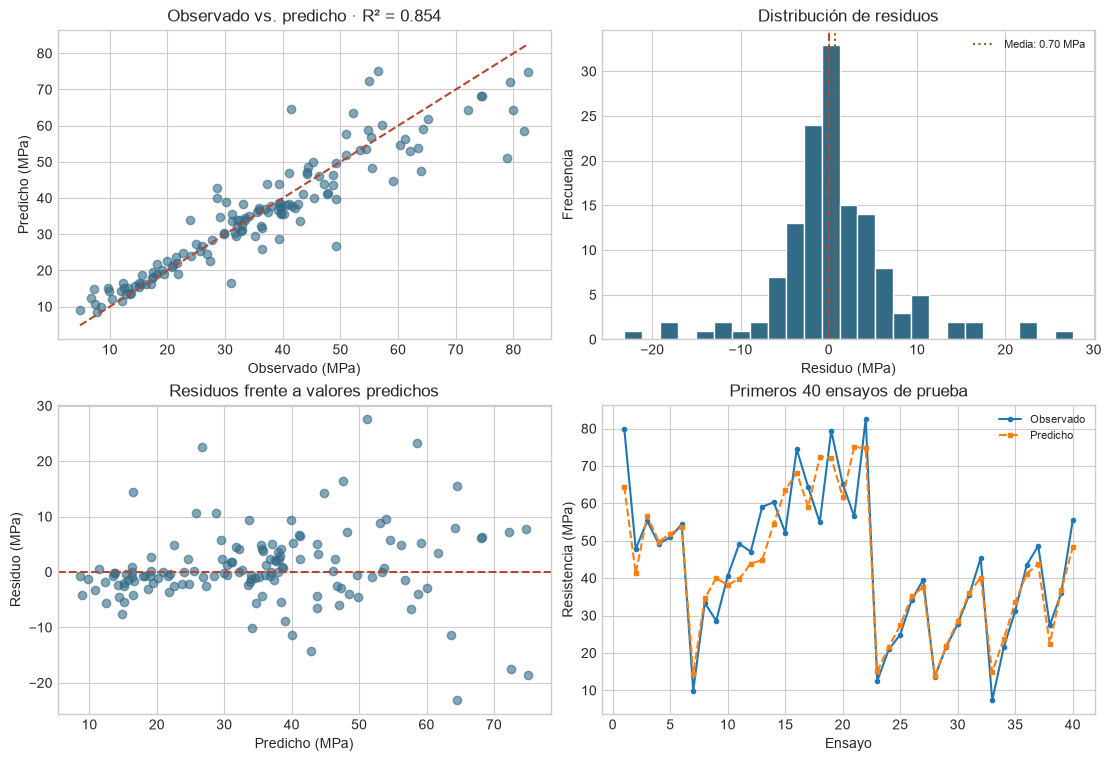

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), layout="constrained")
residuos = y_test.to_numpy() - y_pred
lo, hi = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())

axes[0, 0].scatter(y_test, y_pred, alpha=0.6, color="#336b87")
axes[0, 0].plot([lo, hi], [lo, hi], "--", color="#b24832")
axes[0, 0].set(title=f"Observado vs. predicho · R² = {metricas['R²']:.3f}",
               xlabel="Observado (MPa)", ylabel="Predicho (MPa)")

axes[0, 1].hist(residuos, bins=25, color="#336b87", edgecolor="white")
axes[0, 1].axvline(0, color="#b24832", linestyle="--")
axes[0, 1].axvline(residuos.mean(), color="#87611e", linestyle=":",
                  label=f"Media: {residuos.mean():.2f} MPa")
axes[0, 1].set(title="Distribución de residuos", xlabel="Residuo (MPa)", ylabel="Frecuencia")
axes[0, 1].legend(fontsize=8)

axes[1, 0].scatter(y_pred, residuos, alpha=0.6, color="#336b87")
axes[1, 0].axhline(0, color="#b24832", linestyle="--")
axes[1, 0].set(title="Residuos frente a valores predichos", xlabel="Predicho (MPa)", ylabel="Residuo (MPa)")

n = min(40, len(y_test))
axes[1, 1].plot(np.arange(1, n + 1), y_test.iloc[:n], "o-", markersize=3, label="Observado")
axes[1, 1].plot(np.arange(1, n + 1), y_pred[:n], "s--", markersize=3, label="Predicho")
axes[1, 1].set(title=f"Primeros {n} ensayos de prueba", xlabel="Ensayo", ylabel="Resistencia (MPa)")
axes[1, 1].legend(fontsize=8)
plt.show()

## 8. Pesos de la primera capa

Se calcula la media del peso absoluto de cada entrada y se normaliza a porcentajes. Es una lectura descriptiva de la primera capa. La sección final mide cuánto cambia el desempeño al alterar cada predictor.

,Peso relativo (%)
edad_dias,16.708
agua,14.000
cemento,13.826
superplastificante,11.537
escoria,11.504
agregado_fino,11.389
agregado_grueso,10.851
ceniza_volante,10.185


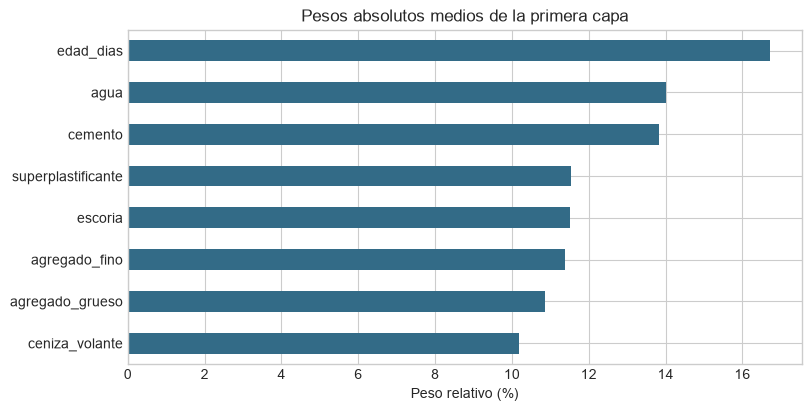

In [11]:
pesos = np.abs(modelo.get_layer("oculta_1").get_weights()[0]).mean(axis=1)
importancia_pesos = pd.Series(100 * pesos / pesos.sum(), index=X.columns, name="Peso relativo (%)").sort_values()
display(importancia_pesos.sort_values(ascending=False).round(3).to_frame())
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
importancia_pesos.plot.barh(ax=ax, color="#336b87")
ax.set(title="Pesos absolutos medios de la primera capa", xlabel="Peso relativo (%)")
plt.show()

## 9. Predicción para nuevas mezclas

Las tres observaciones hipotéticas comparten composición y cambian la edad de curado. También se incluye una receta personalizada. Se aplica el escalador aprendido y se regresa la predicción a MPa.

In [12]:
mezclas = pd.DataFrame([
    [300, 90, 75, 175, 7, 1000, 760, 7],
    [300, 90, 75, 175, 7, 1000, 760, 28],
    [300, 90, 75, 175, 7, 1000, 760, 90],
], columns=X.columns, index=["7 días", "28 días", "90 días"])

def predecir_mezclas(nuevas):
    escaladas = scaler_X.transform(nuevas.loc[:, X.columns]).astype("float32")
    return nuevas.assign(prediccion_mpa=predecir_mpa(escaladas))


display(predecir_mezclas(mezclas).round(2))
personalizada = pd.DataFrame(
    [[340, 40, 55, 165, 8, 1010, 750, 28]], columns=X.columns, index=["Personalizada"],
)
display(predecir_mezclas(personalizada).round(2))

,cemento,escoria,ceniza_volante,agua,superplastificante,agregado_grueso,agregado_fino,edad_dias,prediccion_mpa
7 días,300,90,75,175,7,1000,760,7,31.240000
28 días,300,90,75,175,7,1000,760,28,45.650002
90 días,300,90,75,175,7,1000,760,90,54.500000


,cemento,escoria,ceniza_volante,agua,superplastificante,agregado_grueso,agregado_fino,edad_dias,prediccion_mpa
Personalizada,340,40,55,165,8,1010,750,28,49.540001


## 10. Resumen del ajuste

In [13]:
print(f"Conclusión · Red densa de Keras con {len(historial)} épocas ejecutadas y mejor época {mejor_epoca}.")
print(f"En prueba: RMSE {metricas['RMSE (MPa)']:.2f} MPa, "
      f"MAE {metricas['MAE (MPa)']:.2f} MPa, R² {metricas['R²']:.4f}.")
print(f"Recetas de prueba: {grupos.iloc[prueba].nunique()} | Ensayos de prueba: {len(y_test)}")

Conclusión · Red densa de Keras con 194 épocas ejecutadas y mejor época 164.
En prueba: RMSE 6.89 MPa, MAE 4.53 MPa, R² 0.8544.
Recetas de prueba: 65 | Ensayos de prueba: 138


## 11. Importancia por permutación

Se permuta un predictor por vez en prueba y se mide la caída de R² respecto a las predicciones originales. En ambos casos se calcula R² con predicciones desescaladas en MPa. Se muestran la media y la desviación estándar de 15 repeticiones. Una caída alta señala dependencia predictiva en esta muestra.

,Caída media de R²,Desv. estándar
cemento,0.9680,0.1604
edad_dias,0.6155,0.0298
escoria,0.3523,0.0431
agua,0.1750,0.0304
ceniza_volante,0.1457,0.0196
agregado_fino,0.0757,0.0172
agregado_grueso,0.0548,0.0185
superplastificante,0.0533,0.0162


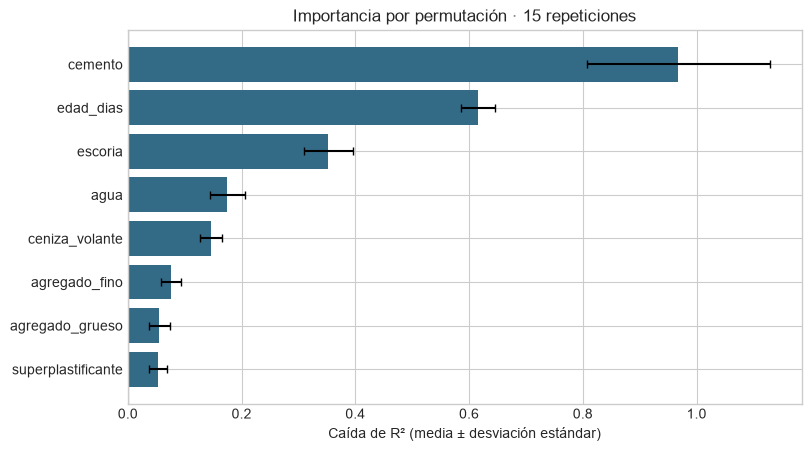

Mayor caída media al permutar: cemento.


In [14]:
rng = np.random.default_rng(SEED)
repeticiones = 15
caidas = {}

for i, columna in enumerate(X.columns):
    perdidas_r2 = []
    for _ in range(repeticiones):
        X_permutado = X_test_sc.copy()
        X_permutado[:, i] = rng.permutation(X_test_sc[:, i])
        pred_permutada = predecir_mpa(X_permutado)
        perdidas_r2.append(metricas["R²"] - r2_score(y_test, pred_permutada))
    caidas[columna] = perdidas_r2

tabla_perm = pd.DataFrame(caidas).agg(["mean", "std"]).T
tabla_perm.columns = ["Caída media de R²", "Desv. estándar"]
tabla_perm = tabla_perm.sort_values("Caída media de R²")
display(tabla_perm.iloc[::-1].round(4))

fig, ax = plt.subplots(figsize=(8, 4.4), layout="constrained")
ax.barh(tabla_perm.index, tabla_perm["Caída media de R²"], xerr=tabla_perm["Desv. estándar"],
        color="#336b87", capsize=3)
ax.axvline(0, color="0.4", linewidth=0.8)
ax.set(title=f"Importancia por permutación · {repeticiones} repeticiones",
       xlabel="Caída de R² (media ± desviación estándar)")
plt.show()
print(f"Mayor caída media al permutar: {tabla_perm.index[-1]}.")